# Atividade II

**Aluno:** Cauê Reis  
**Disciplina:** Business Intelligence

---

**Supermercado da Economia** – Análise de Performance de Vendas  

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [3]:
plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
})

CORES_FILIAL = {'Centro': '#2E86AB', 'Shopping': '#A23B72', 'Bairro': '#F18F01'}
PALETTE_CAT  = ['#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51']

df = pd.read_excel('dados-vendas.xlsx')
df.head()

,Transacao_ID,Cliente_Nome,Filial_Loja,Idade_Cliente,Categoria_Produto,Quantidade_Itens,Valor_Total_Venda,Data_Compra
0,1,Ana Ferreira,Centro,35,Perecíveis,3,45.80,2024-06-03
1,2,Bruno Silva,Shopping,22,Bebidas,6,98.50,2023-04-07
2,3,Carlos Souza,Centro,51,Limpeza,2,22.90,2025-02-25
3,4,Daniela Reis,Bairro,45,Hortifrúti,7,67.25,2023-09-25
4,5,Eduardo Lima,Shopping,29,Açougue,1,85.23,2023-09-23


---
## 1. Análise Exploratória Inicial

### 1a. Descrição e Classificação das Variáveis

In [4]:
print('=' * 60)
print(f'  Dimensões do dataset: {df.shape[0]} linhas × {df.shape[1]} colunas')
print('=' * 60)

tipo_map = {
    'Transacao_ID'      : ('int64',   'Quantitativa Discreta',  'Identificador único de cada transação'),
    'Cliente_Nome'      : ('str',     'Qualitativa Nominal',    'Nome do cliente'),
    'Filial_Loja'       : ('str',     'Qualitativa Nominal',    'Filial onde ocorreu a venda (Centro / Shopping / Bairro)'),
    'Idade_Cliente'     : ('int64',   'Quantitativa Discreta',  'Idade do cliente em anos'),
    'Categoria_Produto' : ('str',     'Qualitativa Nominal',    'Categoria do produto vendido'),
    'Quantidade_Itens'  : ('int64',   'Quantitativa Discreta',  'Número de itens na transação'),
    'Valor_Total_Venda' : ('float64', 'Quantitativa Contínua',  'Valor monetário total da compra (R$)'),
    'Data_Compra'       : ('datetime','Qualitativa Ordinal',    'Data em que a compra foi realizada'),
}

tabela = pd.DataFrame(tipo_map, index=['Dtype','Classificação','Descrição']).T.reset_index()
tabela.columns = ['Variável', 'Dtype', 'Classificação Estatística', 'Descrição']
print(tabela.to_string(index=False))

print('\nValores nulos por coluna:')
print(df.isnull().sum())
print('\nEstatísticas descritivas das variáveis numéricas:')
df[['Idade_Cliente','Quantidade_Itens','Valor_Total_Venda']].describe().round(2)

  Dimensões do dataset: 332 linhas × 8 colunas
         Variável    Dtype Classificação Estatística                                                Descrição
     Transacao_ID    int64     Quantitativa Discreta                    Identificador único de cada transação
     Cliente_Nome      str       Qualitativa Nominal                                          Nome do cliente
      Filial_Loja      str       Qualitativa Nominal Filial onde ocorreu a venda (Centro / Shopping / Bairro)
    Idade_Cliente    int64     Quantitativa Discreta                                 Idade do cliente em anos
Categoria_Produto      str       Qualitativa Nominal                             Categoria do produto vendido
 Quantidade_Itens    int64     Quantitativa Discreta                             Número de itens na transação
Valor_Total_Venda  float64     Quantitativa Contínua                     Valor monetário total da compra (R$)
      Data_Compra datetime       Qualitativa Ordinal                     

,Idade_Cliente,Quantidade_Itens,Valor_Total_Venda
count,332.00,332.00,332.00
mean,38.62,6.54,80.36
std,12.02,3.53,31.46
min,18.00,1.00,22.90
25%,28.00,4.00,52.58
50%,39.00,7.00,80.56
75%,49.00,10.00,107.01
max,59.00,12.00,135.30


### 1b. Totais Gerais

In [5]:
total_vendas = df['Valor_Total_Venda'].sum()
total_itens  = df['Quantidade_Itens'].sum()
n_transacoes = len(df)
ticket_medio = total_vendas / n_transacoes
periodo_ini  = df['Data_Compra'].min().strftime('%d/%m/%Y')
periodo_fim  = df['Data_Compra'].max().strftime('%d/%m/%Y')

print('=' * 50)
print('         RESUMO GERAL DO PERÍODO')
print('=' * 50)
print(f'  Período analisado : {periodo_ini} → {periodo_fim}')
print(f'  Total de transações: {n_transacoes:,}')
print(f'  Soma total de vendas: R$ {total_vendas:,.2f}')
print(f'  Total de itens vendidos: {total_itens:,}')
print(f'  Ticket médio por transação: R$ {ticket_medio:.2f}')
print('=' * 50)

         RESUMO GERAL DO PERÍODO
  Período analisado : 05/01/2021 → 25/07/2025
  Total de transações: 332
  Soma total de vendas: R$ 26,681.04
  Total de itens vendidos: 2,172
  Ticket médio por transação: R$ 80.36


---
## 2. Performance por Filial

### 2a. Gráfico de Barras – Valor Total de Vendas por Filial

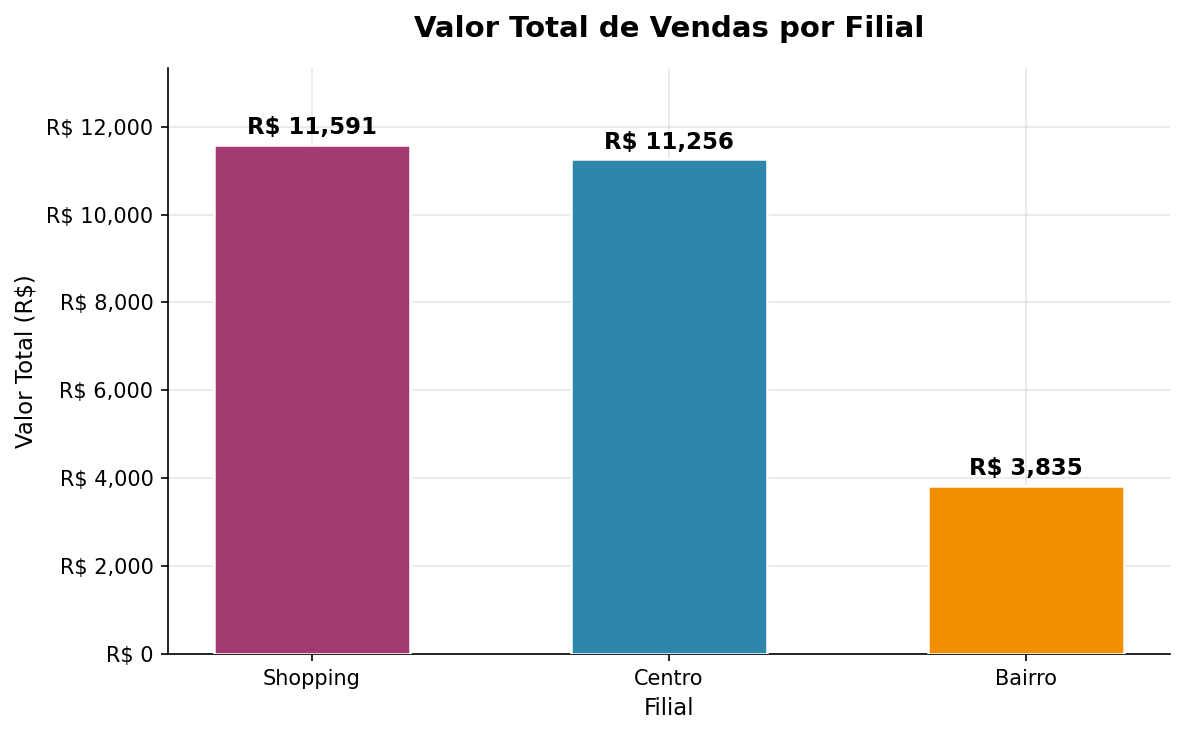

  Filial  Total_Vendas
Shopping      11590.75
  Centro      11255.55
  Bairro       3834.74


In [6]:
vendas_filial = (
    df.groupby('Filial_Loja')['Valor_Total_Venda']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
vendas_filial.columns = ['Filial', 'Total_Vendas']

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    vendas_filial['Filial'],
    vendas_filial['Total_Vendas'],
    color=[CORES_FILIAL[f] for f in vendas_filial['Filial']],
    width=0.55,
    edgecolor='white',
    linewidth=1.2,
    zorder=3
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 120,
        f'R$ {h:,.0f}',
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))
ax.set_title('Valor Total de Vendas por Filial', pad=15)
ax.set_xlabel('Filial')
ax.set_ylabel('Valor Total (R$)')
ax.set_ylim(0, vendas_filial['Total_Vendas'].max() * 1.15)
plt.tight_layout()
plt.savefig('grafico_filial_vendas.png', bbox_inches='tight')
plt.show()
print(vendas_filial.to_string(index=False))

### 2b. Melhor/Pior Desempenho e Média de Itens por Transação

Métricas por Filial:
Filial_Loja  Total_Vendas  Transacoes  Media_Itens  Ticket_Medio
     Bairro       3834.74          50         5.60         76.69
     Centro      11255.55         140         6.86         80.40
   Shopping      11590.75         142         6.56         81.62

 Filial com MELHOR desempenho: Shopping
Filial com PIOR desempenho:   Bairro

Diferença máxima na média de itens entre filiais: 1.26 itens/transação


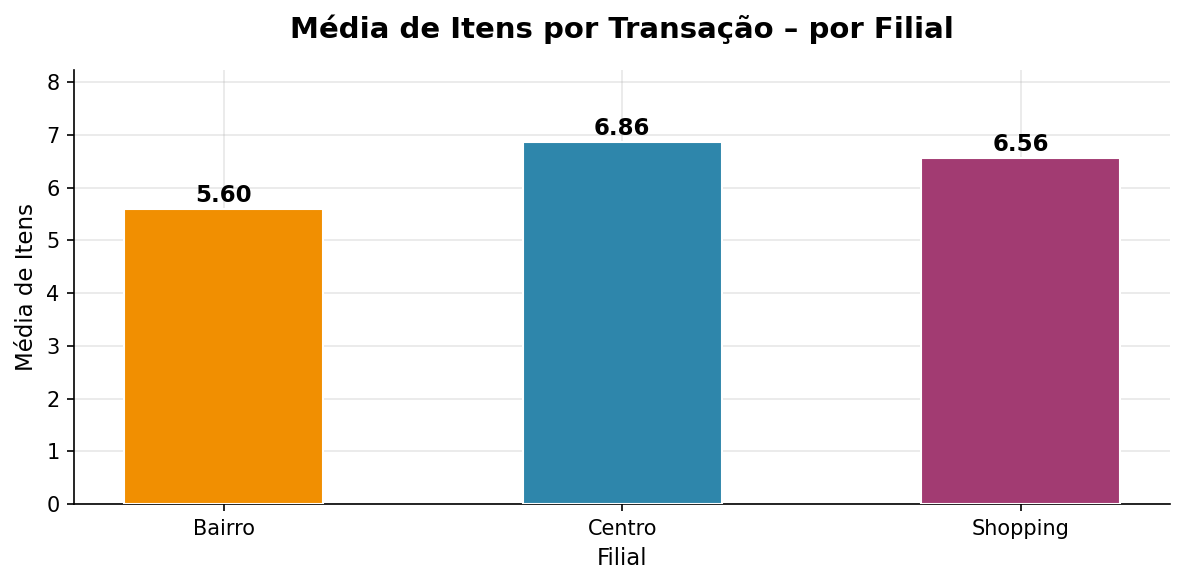

In [7]:
metricas = df.groupby('Filial_Loja').agg(
    Total_Vendas   = ('Valor_Total_Venda', 'sum'),
    Transacoes     = ('Transacao_ID',      'count'),
    Media_Itens    = ('Quantidade_Itens',  'mean'),
    Ticket_Medio   = ('Valor_Total_Venda', 'mean'),
).round(2).reset_index()

print('Métricas por Filial:')
print(metricas.to_string(index=False))

melhor = metricas.loc[metricas['Total_Vendas'].idxmax(), 'Filial_Loja']
pior   = metricas.loc[metricas['Total_Vendas'].idxmin(), 'Filial_Loja']

print(f'\n Filial com MELHOR desempenho: {melhor}')
print(f'Filial com PIOR desempenho:   {pior}')


diff = metricas['Media_Itens'].max() - metricas['Media_Itens'].min()
print(f'\nDiferença máxima na média de itens entre filiais: {diff:.2f} itens/transação')

fig, ax = plt.subplots(figsize=(8, 4))
bars2 = ax.bar(
    metricas['Filial_Loja'],
    metricas['Media_Itens'],
    color=[CORES_FILIAL[f] for f in metricas['Filial_Loja']],
    width=0.5, edgecolor='white', zorder=3
)
for bar in bars2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.04, f'{h:.2f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_title('Média de Itens por Transação – por Filial', pad=15)
ax.set_xlabel('Filial')
ax.set_ylabel('Média de Itens')
ax.set_ylim(0, metricas['Media_Itens'].max() * 1.2)
plt.tight_layout()
plt.savefig('grafico_media_itens.png', bbox_inches='tight')
plt.show()

---
## 3. Análise de Categorias de Produtos

### 3a. Ranking de Categorias por Valor Total de Vendas

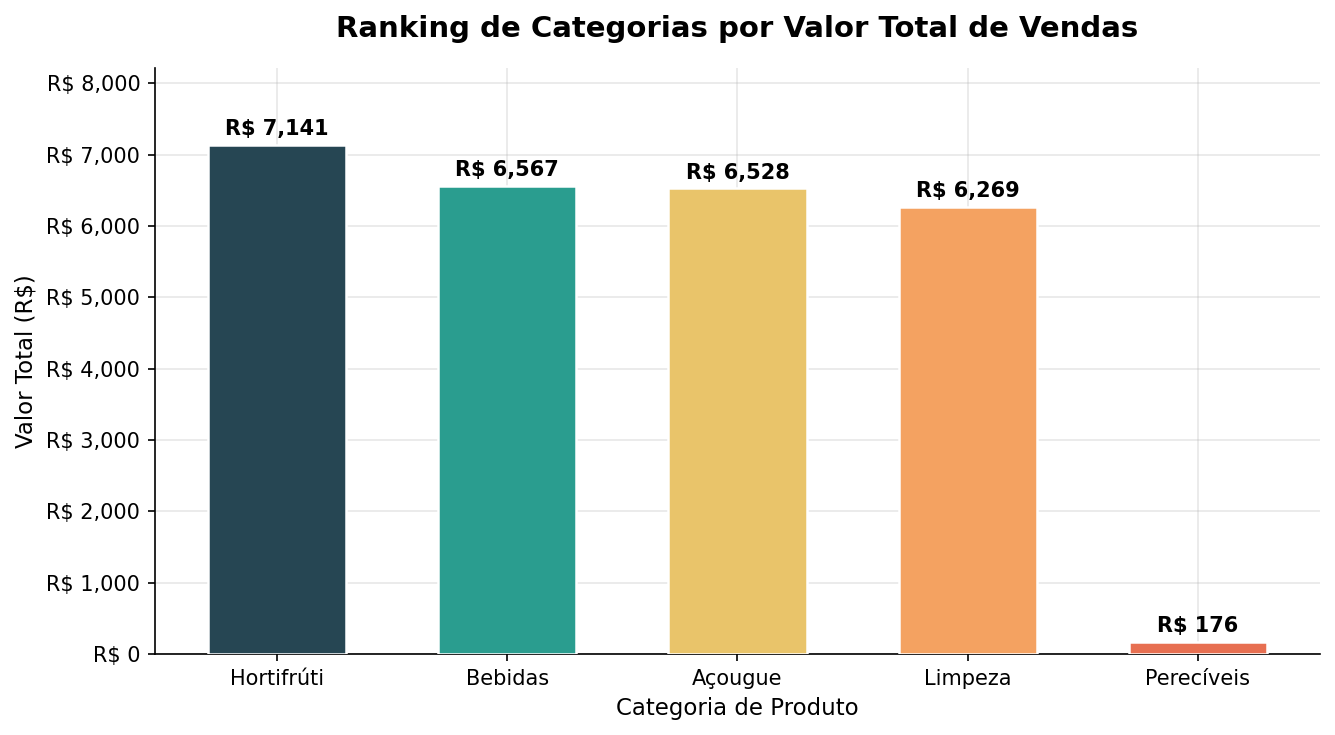

 Categoria  Total_Vendas
Hortifrúti       7140.98
   Bebidas       6567.07
   Açougue       6527.97
   Limpeza       6268.84
Perecíveis        176.18


In [8]:
vendas_cat = (
    df.groupby('Categoria_Produto')['Valor_Total_Venda']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
vendas_cat.columns = ['Categoria', 'Total_Vendas']

fig, ax = plt.subplots(figsize=(9, 5))
bars3 = ax.bar(
    vendas_cat['Categoria'],
    vendas_cat['Total_Vendas'],
    color=PALETTE_CAT,
    width=0.6, edgecolor='white', linewidth=1.2, zorder=3
)
for i, bar in enumerate(bars3):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 80,
            f'R$ {h:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))
ax.set_title('Ranking de Categorias por Valor Total de Vendas', pad=15)
ax.set_xlabel('Categoria de Produto')
ax.set_ylabel('Valor Total (R$)')
ax.set_ylim(0, vendas_cat['Total_Vendas'].max() * 1.15)
plt.tight_layout()
plt.savefig('grafico_categorias_ranking.png', bbox_inches='tight')
plt.show()
print(vendas_cat.to_string(index=False))

### 3b. Categorias Mais/Menos Lucrativas e Ticket Médio

Análise completa por Categoria:
Categoria_Produto  Total_Vendas  Transacoes  Ticket_Medio  Total_Itens
       Hortifrúti       7140.98          91         78.47          596
          Bebidas       6567.07          81         81.07          533
          Açougue       6527.97          79         82.63          515
          Limpeza       6268.84          79         79.35          522
       Perecíveis        176.18           2         88.09            6

 3 Categorias MAIS lucrativas : ['Hortifrúti', 'Bebidas', 'Açougue']
 3 Categorias MENOS lucrativas: ['Açougue', 'Limpeza', 'Perecíveis']
 Maior ticket médio: Perecíveis (R$ 88.09)


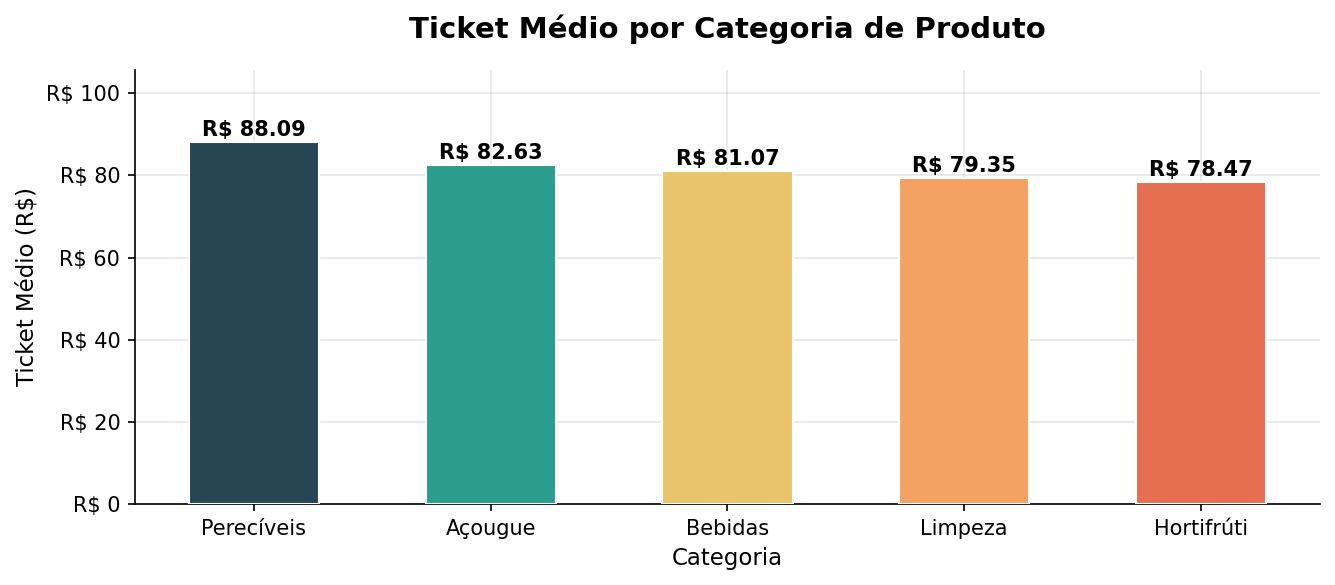

In [9]:
analise_cat = df.groupby('Categoria_Produto').agg(
    Total_Vendas   = ('Valor_Total_Venda', 'sum'),
    Transacoes     = ('Transacao_ID',      'count'),
    Ticket_Medio   = ('Valor_Total_Venda', 'mean'),
    Total_Itens    = ('Quantidade_Itens',  'sum'),
).round(2).sort_values('Total_Vendas', ascending=False).reset_index()

print('Análise completa por Categoria:')
print(analise_cat.to_string(index=False))

top3    = analise_cat.head(3)['Categoria_Produto'].tolist()
bottom3 = analise_cat.tail(3)['Categoria_Produto'].tolist()
maior_ticket = analise_cat.loc[analise_cat['Ticket_Medio'].idxmax(), 'Categoria_Produto']
valor_ticket = analise_cat['Ticket_Medio'].max()

print(f'\n 3 Categorias MAIS lucrativas : {top3}')
print(f' 3 Categorias MENOS lucrativas: {bottom3}')
print(f' Maior ticket médio: {maior_ticket} (R$ {valor_ticket:.2f})')

# Gráfico ticket médio
analise_cat_sorted = analise_cat.sort_values('Ticket_Medio', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
colors_ticket = [PALETTE_CAT[i] for i in range(len(analise_cat_sorted))]
bars4 = ax.bar(
    analise_cat_sorted['Categoria_Produto'],
    analise_cat_sorted['Ticket_Medio'],
    color=colors_ticket, width=0.55, edgecolor='white', zorder=3
)
for bar in bars4:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
            f'R$ {h:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))
ax.set_title('Ticket Médio por Categoria de Produto', pad=15)
ax.set_xlabel('Categoria')
ax.set_ylabel('Ticket Médio (R$)')
ax.set_ylim(0, analise_cat_sorted['Ticket_Medio'].max() * 1.2)
plt.tight_layout()
plt.savefig('grafico_ticket_medio.png', bbox_inches='tight')
plt.show()

---
## 4. Análise de Perfil de Cliente

### 4a. Relação entre Idade e Valor Total da Venda

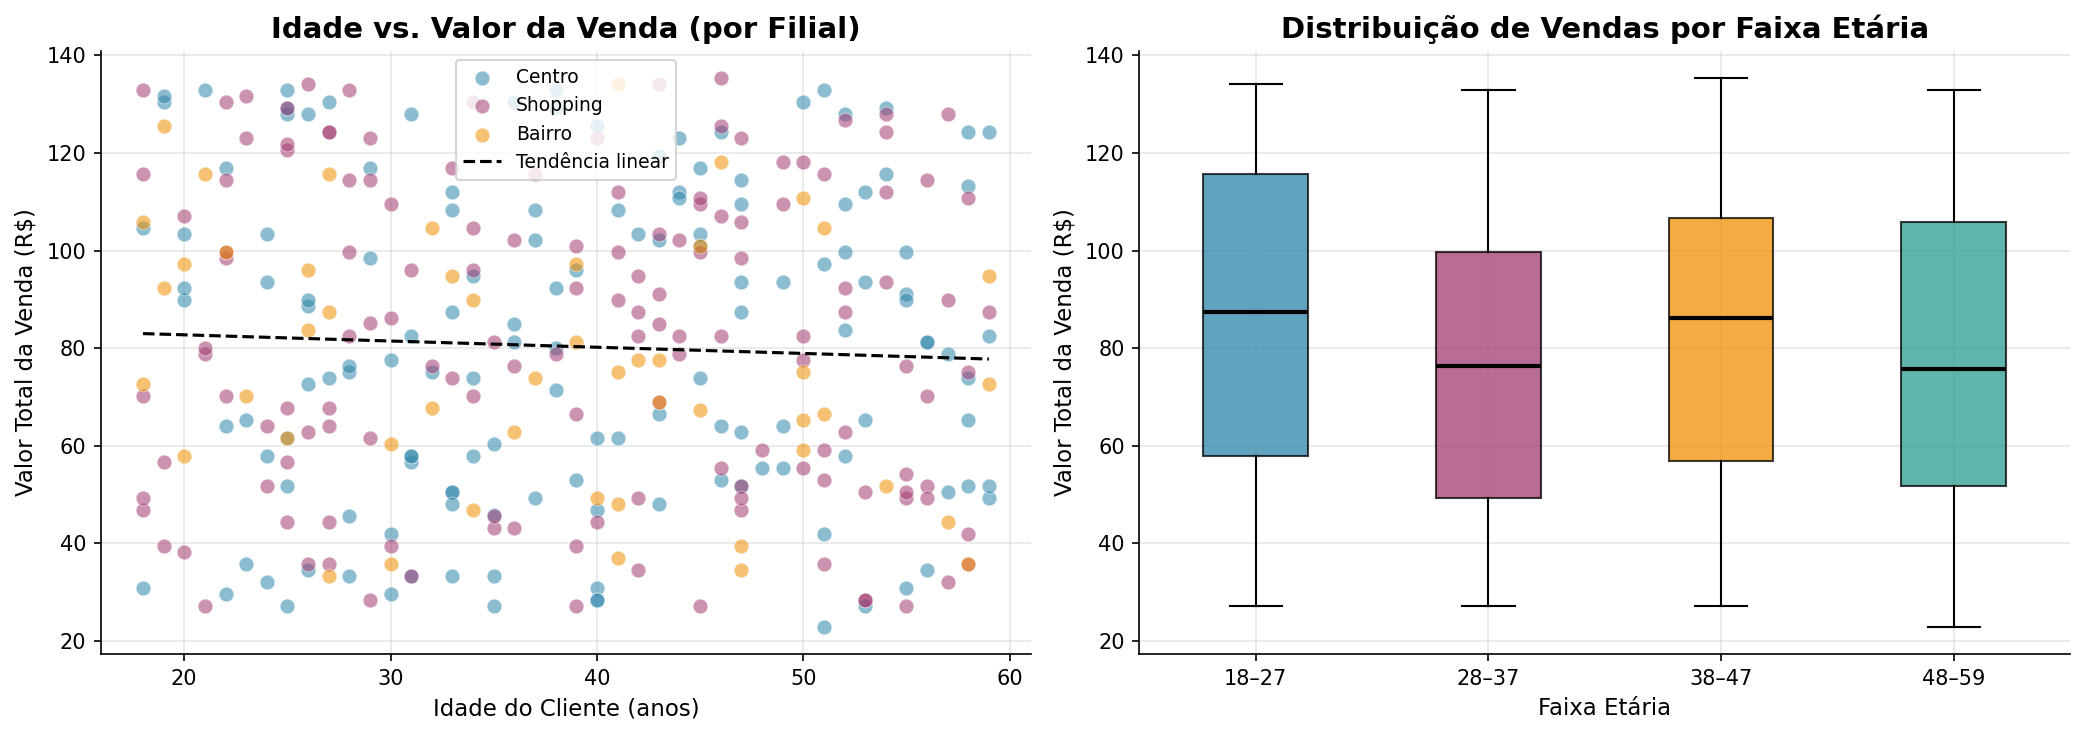

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for filial, cor in CORES_FILIAL.items():
    sub = df[df['Filial_Loja'] == filial]
    ax.scatter(sub['Idade_Cliente'], sub['Valor_Total_Venda'],
               color=cor, alpha=0.55, edgecolors='white', linewidths=0.4,
               s=50, label=filial, zorder=3)

z = np.polyfit(df['Idade_Cliente'], df['Valor_Total_Venda'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['Idade_Cliente'].min(), df['Idade_Cliente'].max(), 100)
ax.plot(x_line, p(x_line), 'k--', linewidth=1.5, label='Tendência linear', zorder=4)
ax.set_title('Idade vs. Valor da Venda (por Filial)')
ax.set_xlabel('Idade do Cliente (anos)')
ax.set_ylabel('Valor Total da Venda (R$)')
ax.legend(fontsize=9)

ax2 = axes[1]
bins   = [18, 28, 38, 48, 60]
labels = ['18–27', '28–37', '38–47', '48–59']
df['Faixa_Etaria'] = pd.cut(df['Idade_Cliente'], bins=bins, labels=labels, right=False)

grupos = [df[df['Faixa_Etaria'] == faixa]['Valor_Total_Venda'].values for faixa in labels]
bp = ax2.boxplot(grupos, patch_artist=True, labels=labels,
                 medianprops=dict(color='black', linewidth=2))
cores_box = ['#2E86AB', '#A23B72', '#F18F01', '#2A9D8F']
for patch, cor in zip(bp['boxes'], cores_box):
    patch.set_facecolor(cor)
    patch.set_alpha(0.75)
ax2.set_title('Distribuição de Vendas por Faixa Etária')
ax2.set_xlabel('Faixa Etária')
ax2.set_ylabel('Valor Total da Venda (R$)')

plt.tight_layout()
plt.savefig('grafico_idade_vendas.png', bbox_inches='tight')
plt.show()

### 4b. Correlação e Faixa Etária Dominante

Correlação de Pearson (Idade × Valor_Total_Venda): r = -0.0486
Interpretação: correlação desprezível (praticamente inexistente)

Vendas por Faixa Etária:
Faixa_Etaria  Total_Vendas  Transacoes  Media_Venda  Media_Idade  %_Vendas
       18–27       6831.52          81        84.34        22.96      25.6
       28–37       5539.34          73        75.88        32.34      20.8
       38–47       7484.15          90        83.16        42.90      28.1
       48–59       6826.03          88        77.57        53.86      25.6

 Faixa etária responsável pela maior parte das vendas: 38–47 (28.1%)


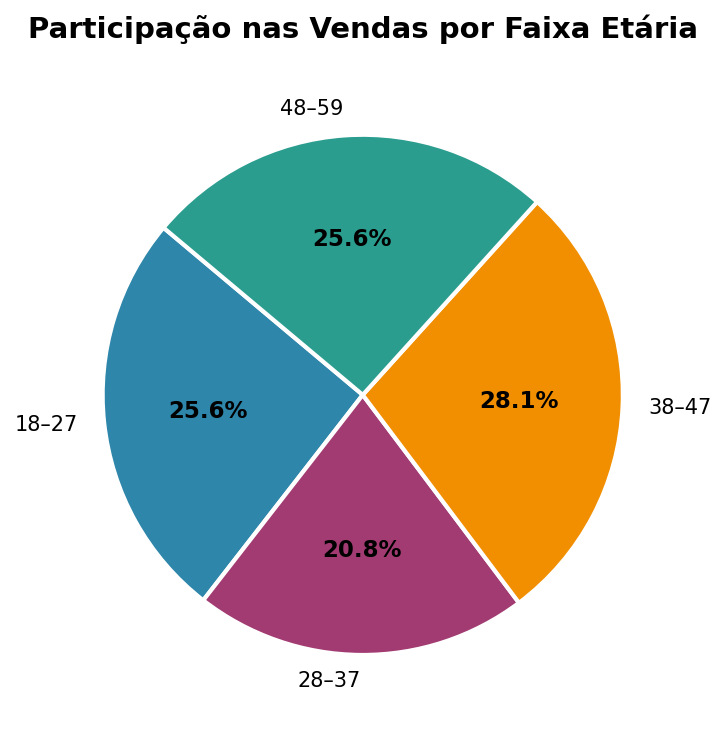

In [12]:
corr = df['Idade_Cliente'].corr(df['Valor_Total_Venda'])
print(f'Correlação de Pearson (Idade × Valor_Total_Venda): r = {corr:.4f}')

if abs(corr) < 0.1:
    interp = 'correlação desprezível (praticamente inexistente)'
elif abs(corr) < 0.3:
    interp = 'correlação fraca'
elif abs(corr) < 0.6:
    interp = 'correlação moderada'
else:
    interp = 'correlação forte'
    
print(f'Interpretação: {interp}\n')

faixa_analise = df.groupby('Faixa_Etaria', observed=True).agg(
    Total_Vendas  = ('Valor_Total_Venda', 'sum'),
    Transacoes    = ('Transacao_ID',      'count'),
    Media_Venda   = ('Valor_Total_Venda', 'mean'),
    Media_Idade   = ('Idade_Cliente',     'mean'),
).round(2).reset_index()

faixa_analise['%_Vendas'] = (faixa_analise['Total_Vendas'] / faixa_analise['Total_Vendas'].sum() * 100).round(1)
print('Vendas por Faixa Etária:')
print(faixa_analise.to_string(index=False))

melhor_faixa = faixa_analise.loc[faixa_analise['Total_Vendas'].idxmax(), 'Faixa_Etaria']
perc         = faixa_analise.loc[faixa_analise['Total_Vendas'].idxmax(), '%_Vendas']
print(f'\n Faixa etária responsável pela maior parte das vendas: {melhor_faixa} ({perc}%)')

fig, ax = plt.subplots(figsize=(7, 5))
wedges, texts, autotexts = ax.pie(
    faixa_analise['Total_Vendas'],
    labels=faixa_analise['Faixa_Etaria'],
    autopct='%1.1f%%',
    colors=['#2E86AB', '#A23B72', '#F18F01', '#2A9D8F'],
    startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax.set_title('Participação nas Vendas por Faixa Etária', pad=15)
plt.tight_layout()
plt.savefig('grafico_faixa_etaria.png', bbox_inches='tight')
plt.show()

---
## 5. Análise Complementar – Evolução Temporal e Heatmap

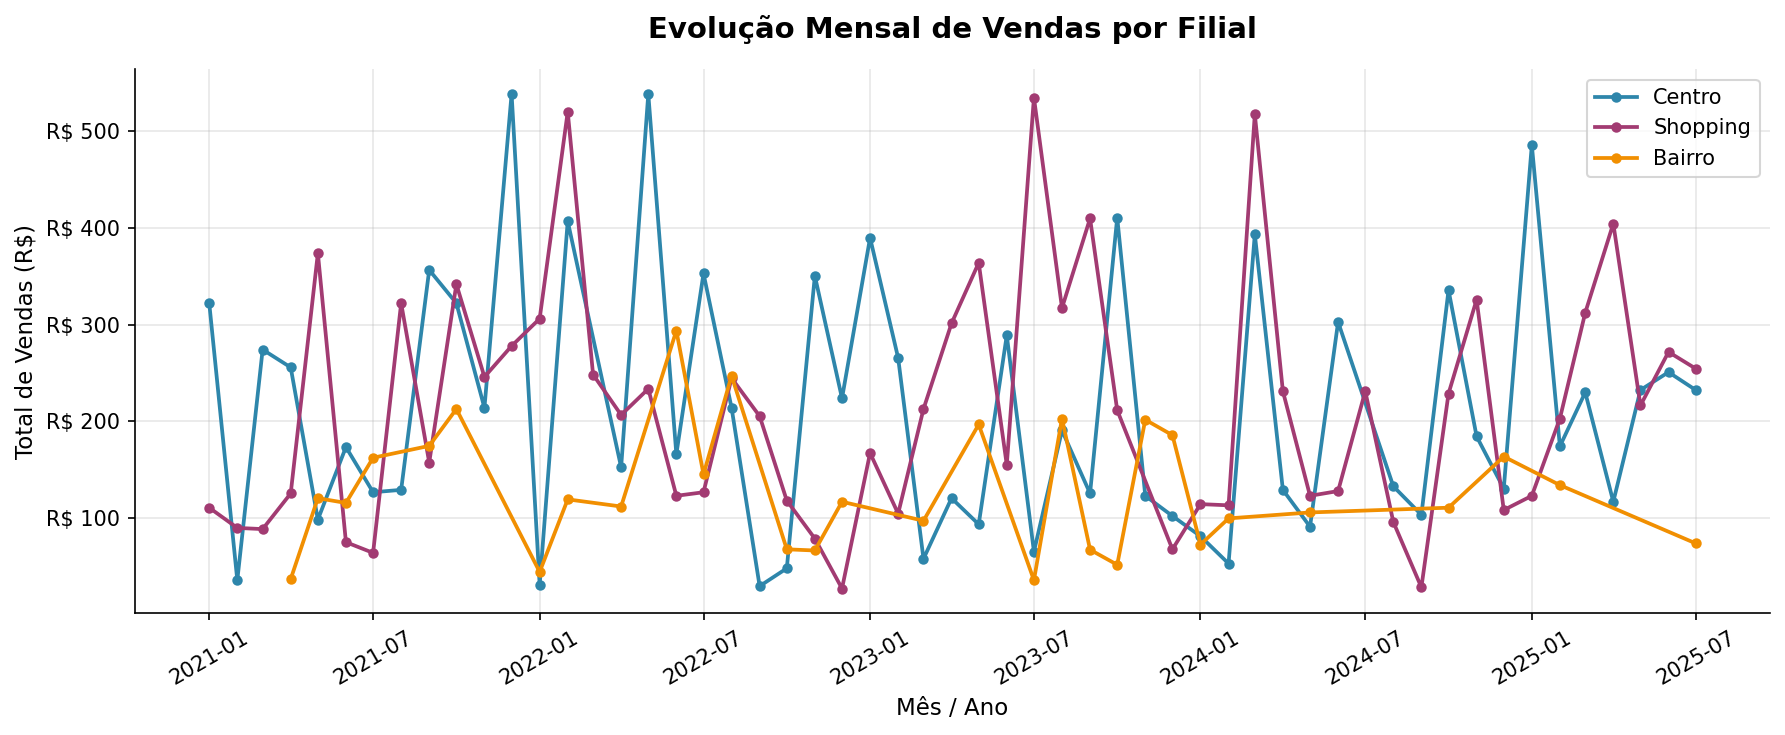

In [13]:
df['AnoMes'] = df['Data_Compra'].dt.to_period('M')
evolucao = (
    df.groupby(['AnoMes', 'Filial_Loja'])['Valor_Total_Venda']
    .sum()
    .reset_index()
)
evolucao['AnoMes_dt'] = evolucao['AnoMes'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
for filial, cor in CORES_FILIAL.items():
    sub = evolucao[evolucao['Filial_Loja'] == filial].sort_values('AnoMes_dt')
    ax.plot(sub['AnoMes_dt'], sub['Valor_Total_Venda'],
            marker='o', markersize=4, color=cor, label=filial, linewidth=1.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))
ax.set_title('Evolução Mensal de Vendas por Filial', pad=15)
ax.set_xlabel('Mês / Ano')
ax.set_ylabel('Total de Vendas (R$)')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('grafico_evolucao_temporal.png', bbox_inches='tight')
plt.show()

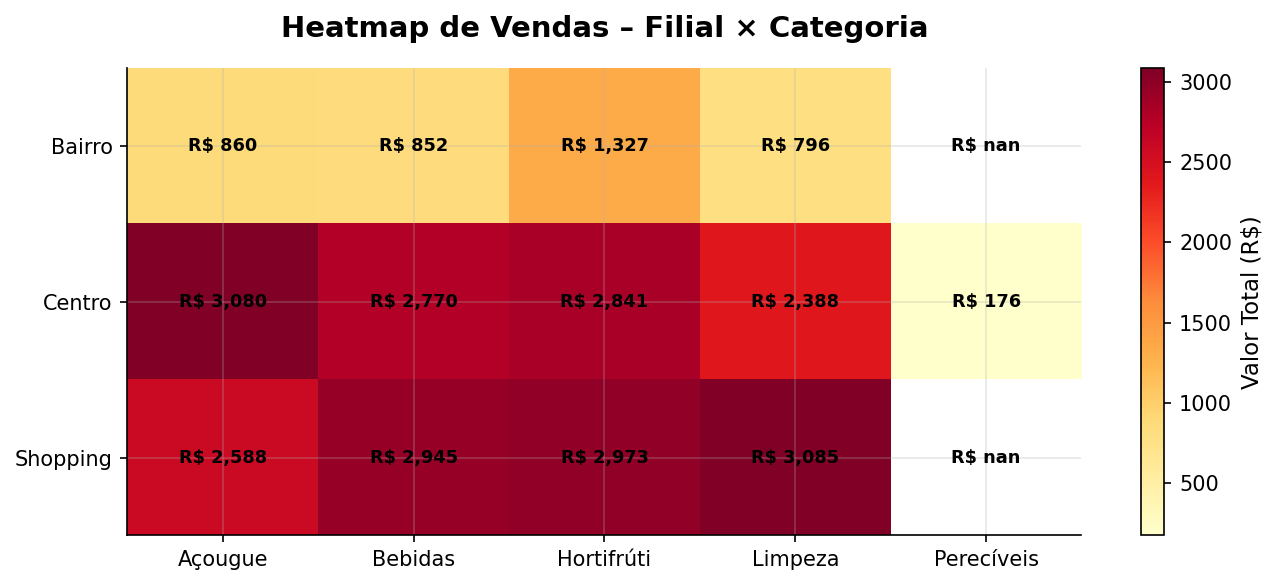

Categoria_Produto  Açougue  Bebidas  Hortifrúti  Limpeza  Perecíveis
Filial_Loja                                                         
Bairro               860.0    852.0      1327.0    796.0         NaN
Centro              3080.0   2770.0      2841.0   2388.0       176.0
Shopping            2588.0   2945.0      2973.0   3085.0         NaN


In [14]:
heatmap_data = df.pivot_table(
    values='Valor_Total_Venda',
    index='Filial_Loja',
    columns='Categoria_Produto',
    aggfunc='sum'
).round(0)

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto')

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, fontsize=10)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index, fontsize=10)

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        val = heatmap_data.values[i, j]
        ax.text(j, i, f'R$ {val:,.0f}', ha='center', va='center',
                fontsize=8.5, fontweight='bold',
                color='white' if val > heatmap_data.values.max() * 0.6 else 'black')

plt.colorbar(im, ax=ax, label='Valor Total (R$)')
ax.set_title('Heatmap de Vendas – Filial × Categoria', pad=15)
plt.tight_layout()
plt.savefig('grafico_heatmap.png', bbox_inches='tight')
plt.show()
print(heatmap_data.to_string())

---
## 6. Síntese Executiva

In [16]:
melhor_filial = metricas.loc[metricas['Total_Vendas'].idxmax()]
pior_filial   = metricas.loc[metricas['Total_Vendas'].idxmin()]
cat_top1      = analise_cat.iloc[0]
cat_bot1      = analise_cat.iloc[-1]
maior_tk_cat  = analise_cat.loc[analise_cat['Ticket_Medio'].idxmax()]

print('=' * 65)
print('               SÍNTESE EXECUTIVA')
print('=' * 65)
print(f'\n Período: {periodo_ini} a {periodo_fim}')
print(f' {n_transacoes} transações | R$ {total_vendas:,.2f} total | {total_itens:,} itens')
print(f'\n Melhor filial: {melhor_filial["Filial_Loja"]} '
      f'(R$ {melhor_filial["Total_Vendas"]:,.2f} | '
      f'{melhor_filial["Transacoes"]} transações)')
print(f' Pior filial:  {pior_filial["Filial_Loja"]} '
      f'(R$ {pior_filial["Total_Vendas"]:,.2f} | '
      f'{pior_filial["Transacoes"]} transações)')
print(f'\n Categoria mais lucrativa:  {cat_top1["Categoria_Produto"]} '
      f'(R$ {cat_top1["Total_Vendas"]:,.2f})')
print(f' Categoria menos lucrativa: {cat_bot1["Categoria_Produto"]} '
      f'(R$ {cat_bot1["Total_Vendas"]:,.2f})')
print(f' Maior ticket médio: {maior_tk_cat["Categoria_Produto"]} '
      f'(R$ {maior_tk_cat["Ticket_Medio"]:.2f})')
print(f'\n Faixa etária de maior volume de vendas: {melhor_faixa} ({perc}% do total)')
print(f' Correlação Idade × Valor: r = {corr:.4f} → {interp}')
print('=' * 65)

               SÍNTESE EXECUTIVA

 Período: 05/01/2021 a 25/07/2025
 332 transações | R$ 26,681.04 total | 2,172 itens

 Melhor filial: Shopping (R$ 11,590.75 | 142 transações)
 Pior filial:  Bairro (R$ 3,834.74 | 50 transações)

 Categoria mais lucrativa:  Hortifrúti (R$ 7,140.98)
 Categoria menos lucrativa: Perecíveis (R$ 176.18)
 Maior ticket médio: Perecíveis (R$ 88.09)

 Faixa etária de maior volume de vendas: 38–47 (28.1% do total)
 Correlação Idade × Valor: r = -0.0486 → correlação desprezível (praticamente inexistente)
